## Methods

1. **Linear SVM with five-fold cross-validation:** Train a linear support vector machine on four folds and validate it on the remaining fold, repeating this process across all five folds.

2. **Approximate RBF-kernel SVM:** Use Random Fourier Features to approximate the RBF kernel and train an SVM without constructing a full kernel matrix.

3. **Neural networks with custom relation-selected features:** Compare an MSE network with a linear output and a cross-entropy network with a sigmoid output using features selected by our custom feature-label score.

4. **L2-regularized logistic regression:** Train logistic regression on the processed features with an L2 penalty on its weights.

5. **L2-regularized neural network with 296 raw features and 28 hidden units:** Expand the raw features using one-hot encoding and missing-value indicators, then train a neural network with one 28-unit hidden layer and L2 regularization.

## Load the dataset

In [1]:
from helpers import load_csv_data

dataset_path = "../data/dataset/"
x_train, x_test, y_train, train_ids, test_ids = load_csv_data(data_path=dataset_path)

## PreProcessing

In [2]:
import os
import numpy as np

from data_processing import (
    standardize, stratified_holdout_indices, stratified_kfold_indices,
    make_splits, expend_data, fit_preprocessor, transform_preprocessor,
    select_expanded_features, transform_nn_input,
)
from data_relation import check_corelation
from basic_fuctions import (
    generate_w, plot_draw, classification_metrics, print_metrics,
)
from SVM import train_linear_svm, fit_rff, transform_rff
from logistic import train_logistic, predict_scores
from NN import (
    forward_NN, train_NN_mse, forward_NN_cross_entropy,
    train_NN_cross_entropy, train_encoded_nn, predict_encoded_nn,
    train_encoded_nn_full,
)

seed = 2026
nn_hidden_dim, nn_epochs, nn_batch_size, nn_gamma = 28, 125, 1024, 0.015
nn_lambda, nn_check_every = 0.0001, 5
relation_threshold, threshold_num = 0.01, 51
accuracy_weight, f1_weight = 0.1, 0.9
svm_epochs, svm_batch_size, svm_learning_rate, svm_lambda = 5, 2048, 0.05, 0.001
lr_epochs, lr_batch_size, lr_gamma, lr_lambda = 100, 4096, 0.05, 0.0001

x_train = x_train.astype(np.float32)
x_test = x_test.astype(np.float32)
with open(dataset_path + "x_train.csv", encoding="utf-8-sig") as file:
    feature_names = file.readline().strip().split(",")[1:]
print("Train / test shapes:", x_train.shape, x_test.shape)

train_indices, valid_indices, holdout_indices = make_splits(y_train, seed=seed)
raw_feature_indices = select_expanded_features(x_train[train_indices], feature_names)
selected_feature_names = [feature_names[index] for index in raw_feature_indices]
x_selected = x_train[:, raw_feature_indices]

feature_schema = fit_preprocessor(
    x_selected[train_indices], selected_feature_names, keep_all_features=True)
encoded_fit = transform_nn_input(x_selected[train_indices], feature_schema, "onehot_missing")
encoded_valid = transform_nn_input(x_selected[valid_indices], feature_schema, "onehot_missing")
encoded_holdout = transform_nn_input(x_selected[holdout_indices], feature_schema, "onehot_missing")
print("Selected raw features:", len(raw_feature_indices))
print("Train / validation / holdout:", len(train_indices), len(valid_indices), len(holdout_indices))
print("Encoded inputs:", encoded_fit.shape[1])

Train / test shapes: (328135, 321) (109379, 321)
Selected raw features: 296
Train / validation / holdout: 229693 49221 49221
Encoded inputs: 1565


## 1. Linear SVM

Linear SVM fold 1: accuracy=0.7286, balanced_accuracy=0.7745, precision=0.2223, recall=0.8304, f1=0.3508
  TP=4812, TN=43002, FP=16830, FN=983
Linear SVM fold 2: accuracy=0.7317, balanced_accuracy=0.7700, precision=0.2224, recall=0.8166, f1=0.3496
  TP=4732, TN=43287, FP=16545, FN=1063
Linear SVM fold 3: accuracy=0.7323, balanced_accuracy=0.7746, precision=0.2243, recall=0.8261, f1=0.3528
  TP=4787, TN=43273, FP=16559, FN=1008
Linear SVM fold 4: accuracy=0.7302, balanced_accuracy=0.7745, precision=0.2231, recall=0.8283, f1=0.3515
  TP=4800, TN=43119, FP=16713, FN=995
Linear SVM fold 5: accuracy=0.7251, balanced_accuracy=0.7727, precision=0.2201, recall=0.8305, f1=0.3480
  TP=4813, TN=42776, FP=17056, FN=982

Five-fold mean:
accuracy: 0.7296 +/- 0.0026
balanced_accuracy: 0.7733 +/- 0.0018
precision: 0.2224 +/- 0.0014
recall: 0.8264 +/- 0.0052
f1: 0.3505 +/- 0.0016


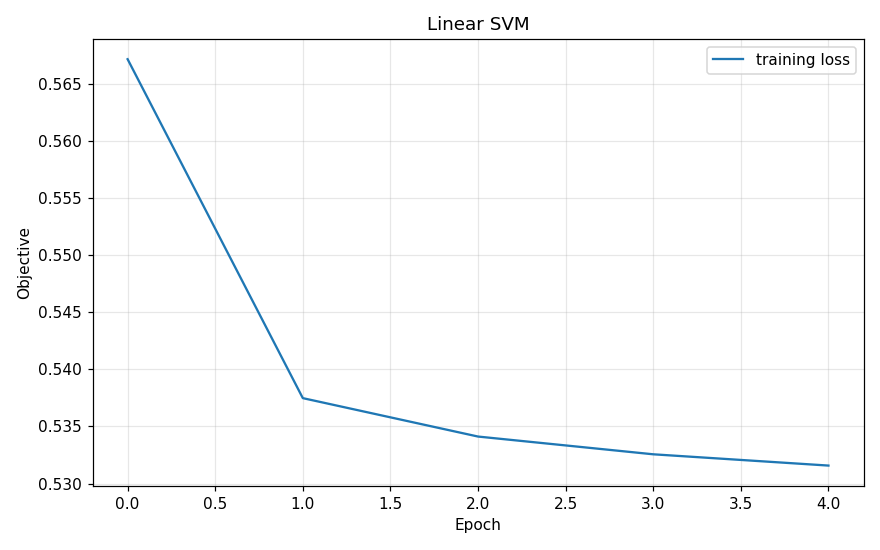

In [3]:
linear_fold_metrics, linear_fold_losses, linear_models = [], [], []
for fold, (fold_train_indices, fold_valid_indices) in enumerate(
        stratified_kfold_indices(y_train, n_splits=5, seed=seed), start=1):
    fold_fit, fold_mean, fold_std = standardize(x_selected[fold_train_indices], return_stats=True)
    fold_valid = x_selected[fold_valid_indices].astype(float).copy()
    fold_nan = np.isnan(fold_valid)
    fold_valid = (fold_valid - fold_mean) / fold_std
    fold_valid[fold_nan] = 0
    fold_w, fold_bias, fold_losses = train_linear_svm(
        fold_fit, y_train[fold_train_indices], epochs=svm_epochs,
        batch_size=svm_batch_size, learning_rate=svm_learning_rate,
        lambda_=svm_lambda, seed=seed + fold)
    fold_scores = fold_valid @ fold_w + fold_bias
    fold_metrics = classification_metrics(y_train[fold_valid_indices], fold_scores)
    linear_fold_metrics.append(fold_metrics)
    linear_fold_losses.append(fold_losses)
    linear_models.append((fold_w, fold_bias, fold_mean, fold_std))
    print_metrics("Linear SVM fold " + str(fold), fold_metrics)

print("\nFive-fold mean:")
for metric_name in ["accuracy", "balanced_accuracy", "precision", "recall", "f1"]:
    values = [metrics[metric_name] for metrics in linear_fold_metrics]
    print(f"{metric_name}: {np.mean(values):.4f} +/- {np.std(values):.4f}")
plot_draw(np.mean(linear_fold_losses, axis=0), "training loss", "Linear SVM", "Epoch", "Objective")
del fold_fit, fold_valid, fold_nan, fold_scores

## 2. RBF SVM

RBF gamma: 0.0016891891891891893
RBF SVM validation: accuracy=0.8924, balanced_accuracy=0.5917, precision=0.3373, recall=0.2266, f1=0.2711
  TP=1313, TN=57252, FP=2580, FN=4482


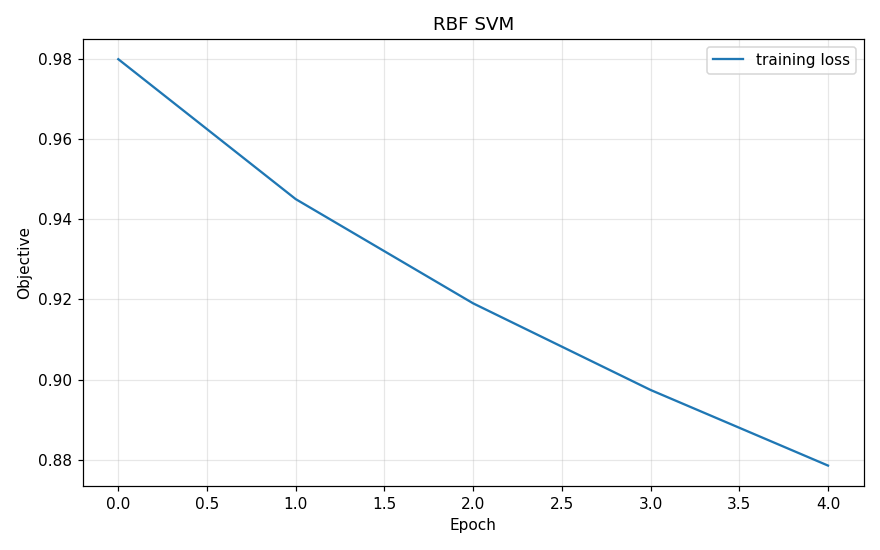

In [4]:
svm_train_indices, svm_valid_indices = stratified_holdout_indices(y_train, seed=seed)
svm_fit, svm_mean, svm_std = standardize(x_selected[svm_train_indices], return_stats=True)
svm_valid = x_selected[svm_valid_indices].astype(float).copy()
svm_nan = np.isnan(svm_valid)
svm_valid = (svm_valid - svm_mean) / svm_std
svm_valid[svm_nan] = 0

rbf_omega, rbf_phase, rbf_gamma = fit_rff(
    svm_fit.shape[1], n_components=128, gamma=None, seed=seed)
rbf_fit = transform_rff(svm_fit, rbf_omega, rbf_phase)
rbf_valid = transform_rff(svm_valid, rbf_omega, rbf_phase)
rbf_w, rbf_bias, rbf_losses = train_linear_svm(
    rbf_fit, y_train[svm_train_indices], epochs=svm_epochs,
    batch_size=svm_batch_size, learning_rate=svm_learning_rate,
    lambda_=svm_lambda, seed=seed)
rbf_scores = rbf_valid @ rbf_w + rbf_bias
rbf_metrics = classification_metrics(y_train[svm_valid_indices], rbf_scores)
print("RBF gamma:", rbf_gamma)
print_metrics("RBF SVM validation", rbf_metrics)
plot_draw(rbf_losses, "training loss", "RBF SVM", "Epoch", "Objective")
del svm_fit, svm_valid, svm_nan, rbf_fit, rbf_valid, rbf_scores

## 3. Relation-selected NN

In [5]:
relation_train_indices, relation_valid_indices = stratified_holdout_indices(y_train)
relation_cols, relation_scores = check_corelation(
    x_train[relation_train_indices], y_train[relation_train_indices],
    relation_threshold, -relation_threshold)
relation_cols = np.asarray(relation_cols, dtype=int)
x_relation = x_train[:, relation_cols].copy()
if 157 in relation_cols:
    cv_index = np.where(relation_cols == 157)[0][0]
    x_relation[:, cv_index] = np.nan_to_num(x_relation[:, cv_index], nan=0)
relation_standard = np.empty_like(x_relation, dtype=float)
relation_standard[relation_train_indices], relation_mean, relation_std = standardize(
    x_relation[relation_train_indices], return_stats=True)
relation_valid = x_relation[relation_valid_indices].astype(float).copy()
relation_nan = np.isnan(relation_valid)
relation_valid = (relation_valid - relation_mean) / relation_std
relation_valid[relation_nan] = 0
relation_standard[relation_valid_indices] = relation_valid
relation_tx = expend_data(relation_standard)
print("Relation-selected features:", len(relation_cols))

Relation-selected features: 212


### MSE

Best epoch: 62
Threshold: -0.10134396602301209
MSE NN validation: accuracy=0.8683, balanced_accuracy=0.7233, precision=0.3451, recall=0.5472, f1=0.4233
  TP=3171, TN=53815, FP=6017, FN=2624


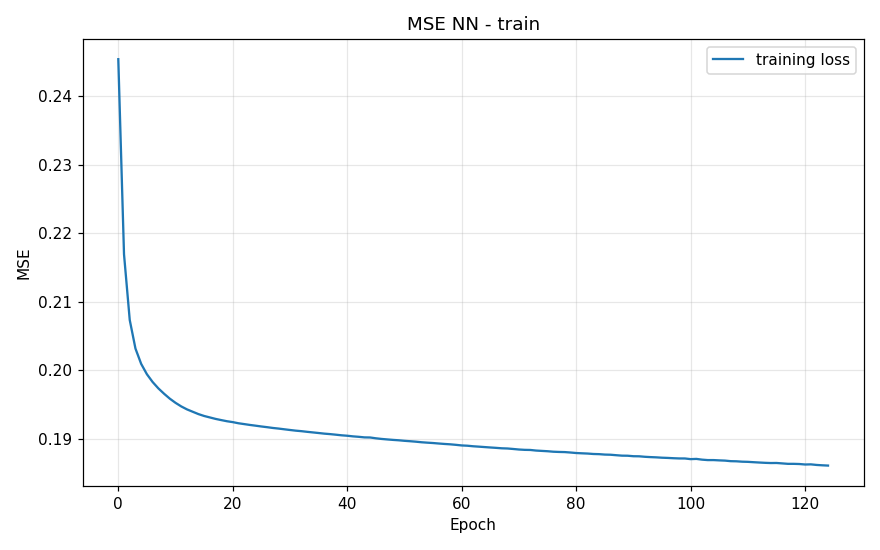

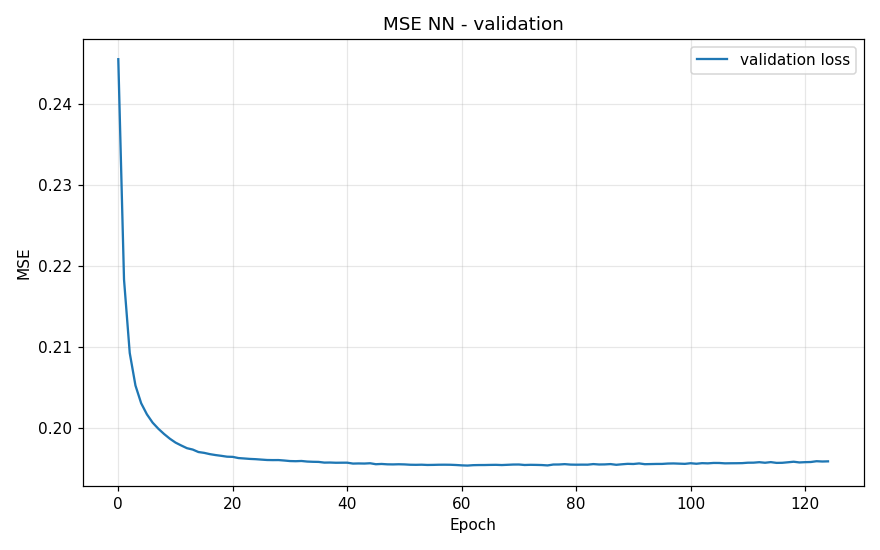

In [6]:
mse_initial_w = [
    generate_w((relation_tx.shape[1], nn_hidden_dim), seed),
    generate_w(nn_hidden_dim + 1, seed + 1),
]
mse_w1, mse_w2, mse_train_losses, mse_valid_losses = train_NN_mse(
    relation_tx, y_train, mse_initial_w, nn_epochs, nn_batch_size, nn_gamma, seed)
mse_scores = forward_NN(relation_tx[relation_valid_indices], mse_w1, mse_w2)[-1]
mse_thresholds = np.unique(np.quantile(mse_scores, np.linspace(0, 1, threshold_num)))
mse_threshold_metrics = [
    classification_metrics(y_train[relation_valid_indices], mse_scores, threshold)
    for threshold in mse_thresholds
]
mse_weighted_scores = [
    accuracy_weight * metrics["accuracy"] + f1_weight * metrics["f1"]
    for metrics in mse_threshold_metrics
]
mse_best_index = np.argmax(mse_weighted_scores)
mse_threshold = mse_thresholds[mse_best_index]
mse_metrics = mse_threshold_metrics[mse_best_index]
print("Best epoch:", np.argmin(mse_valid_losses) + 1)
print("Threshold:", mse_threshold)
print_metrics("MSE NN validation", mse_metrics)
plot_draw(mse_train_losses, "training loss", "MSE NN - train", "Epoch", "MSE")
plot_draw(mse_valid_losses, "validation loss", "MSE NN - validation", "Epoch", "MSE")
del mse_scores

### Sigmoid

Best epoch: 117
Threshold: 0.4529867401444909
Sigmoid NN validation: accuracy=0.8684, balanced_accuracy=0.7235, precision=0.3453, recall=0.5475, f1=0.4235
  TP=3173, TN=53817, FP=6015, FN=2622


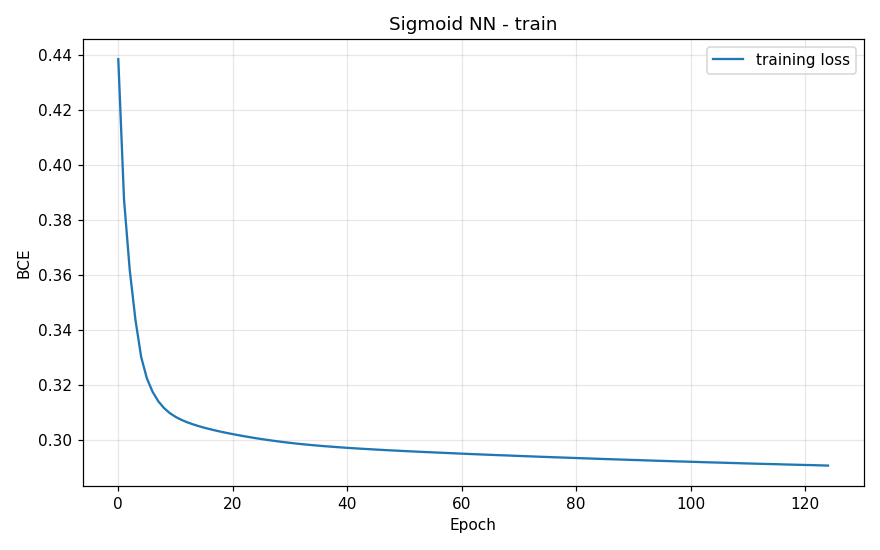

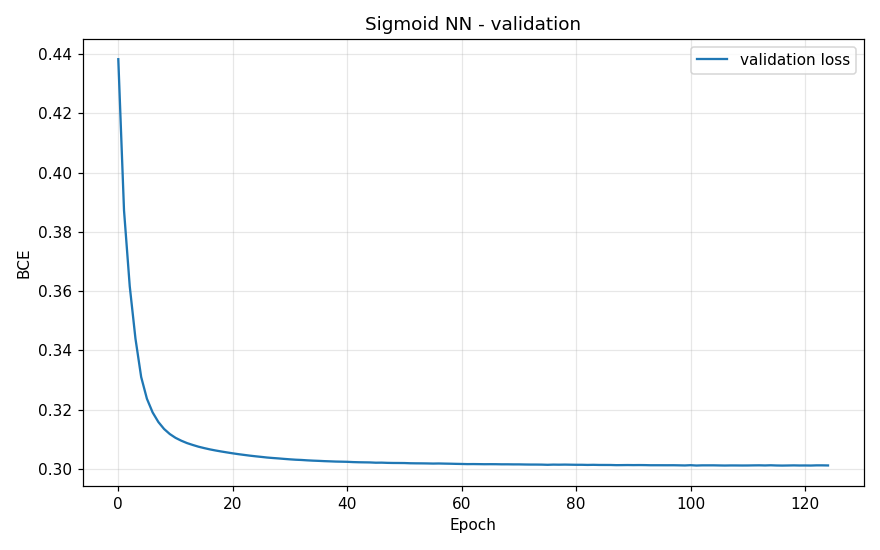

In [7]:
ce_initial_w = [
    generate_w((relation_tx.shape[1], nn_hidden_dim), seed),
    generate_w(nn_hidden_dim + 1, seed + 1),
]
ce_w1, ce_w2, ce_train_losses, ce_valid_losses = train_NN_cross_entropy(
    relation_tx, y_train, ce_initial_w, nn_epochs, nn_batch_size, nn_gamma, seed)
ce_scores = forward_NN_cross_entropy(
    relation_tx[relation_valid_indices], ce_w1, ce_w2)[-1]
ce_thresholds = np.unique(np.quantile(ce_scores, np.linspace(0, 1, threshold_num)))
ce_threshold_metrics = [
    classification_metrics(y_train[relation_valid_indices], ce_scores, threshold)
    for threshold in ce_thresholds
]
ce_weighted_scores = [
    accuracy_weight * metrics["accuracy"] + f1_weight * metrics["f1"]
    for metrics in ce_threshold_metrics
]
ce_best_index = np.argmax(ce_weighted_scores)
ce_threshold = ce_thresholds[ce_best_index]
ce_metrics = ce_threshold_metrics[ce_best_index]
print("Best epoch:", np.argmin(ce_valid_losses) + 1)
print("Threshold:", ce_threshold)
print_metrics("Sigmoid NN validation", ce_metrics)
plot_draw(ce_train_losses, "training loss", "Sigmoid NN - train", "Epoch", "BCE")
plot_draw(ce_valid_losses, "validation loss", "Sigmoid NN - validation", "Epoch", "BCE")
del relation_standard, relation_valid, relation_nan, relation_tx, x_relation, ce_scores

## 4. L2 logistic regression

epoch   1: train_objective=0.23084, valid_bce=0.23067, valid_f1=0.4026, threshold=0.180167
epoch   5: train_objective=0.22255, valid_bce=0.22181, valid_f1=0.4279, threshold=0.192925
epoch  10: train_objective=0.22104, valid_bce=0.22029, valid_f1=0.4331, threshold=0.204211
epoch  15: train_objective=0.22004, valid_bce=0.21939, valid_f1=0.4356, threshold=0.202600
epoch  20: train_objective=0.21948, valid_bce=0.21891, valid_f1=0.4371, threshold=0.170824
epoch  25: train_objective=0.21906, valid_bce=0.21843, valid_f1=0.4380, threshold=0.181177
epoch  30: train_objective=0.21915, valid_bce=0.21867, valid_f1=0.4392, threshold=0.170741
epoch  35: train_objective=0.21861, valid_bce=0.21802, valid_f1=0.4388, threshold=0.185736
epoch  40: train_objective=0.21849, valid_bce=0.21798, valid_f1=0.4395, threshold=0.185836
epoch  45: train_objective=0.21820, valid_bce=0.21767, valid_f1=0.4391, threshold=0.183666
epoch  50: train_objective=0.21850, valid_bce=0.21812, valid_f1=0.4391, threshold=0.183062

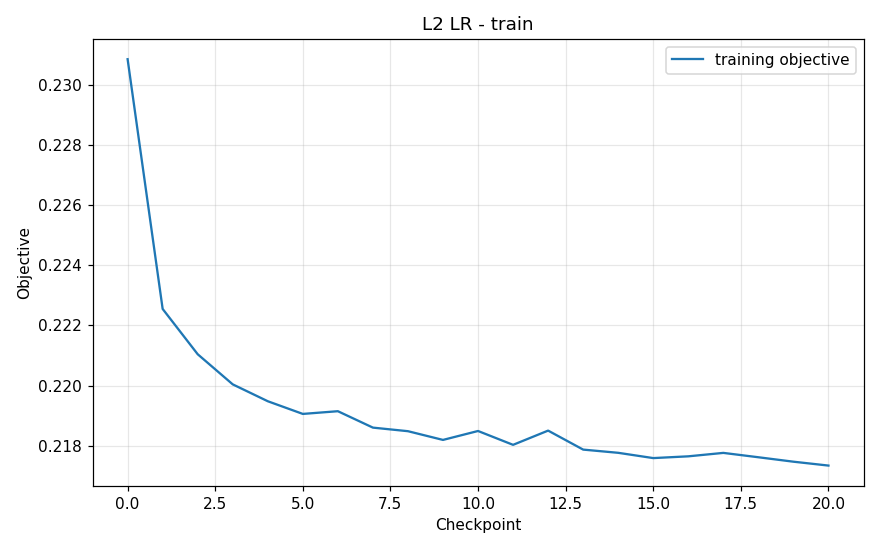

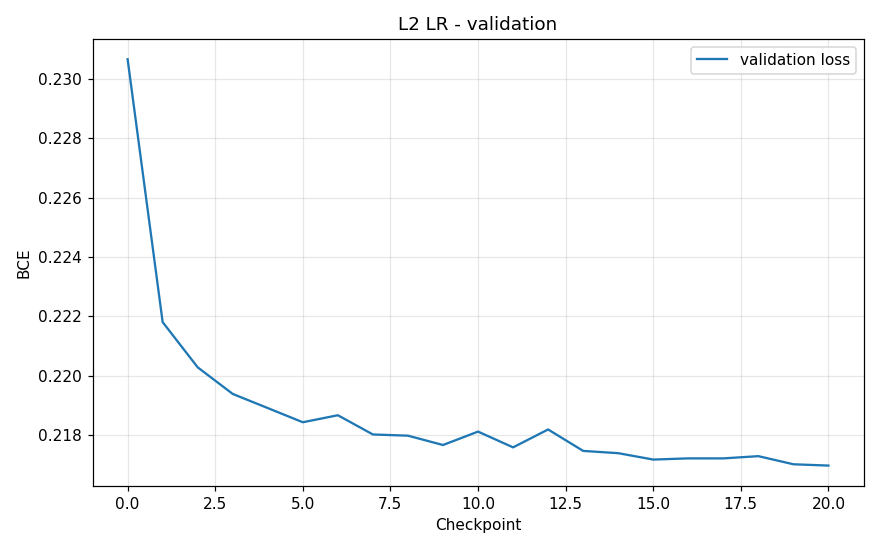

In [8]:
lr_result = train_logistic(
    encoded_fit, y_train[train_indices], encoded_valid, y_train[valid_indices],
    lambda_=lr_lambda, epochs=lr_epochs, batch_size=lr_batch_size,
    gamma=lr_gamma, seed=seed, check_every=5)
lr_holdout_scores = predict_scores(encoded_holdout, lr_result["w"])
lr_holdout_metrics = classification_metrics(
    y_train[holdout_indices], lr_holdout_scores, lr_result["threshold"])
print("Best epoch / threshold:", lr_result["best_epoch"], lr_result["threshold"])
print_metrics("L2 LR validation", lr_result["valid_metrics"])
print_metrics("L2 LR holdout", lr_holdout_metrics)
plot_draw([row["train_objective"] for row in lr_result["history"]],
          "training objective", "L2 LR - train", "Checkpoint", "Objective")
plot_draw([row["valid_bce"] for row in lr_result["history"]],
          "validation loss", "L2 LR - validation", "Checkpoint", "BCE")
del lr_holdout_scores

## 5. L2 NN: 296 raw features, 28 hidden units

epoch   1: train_ce=0.39412, valid_ce=0.39420, valid_f1=0.3246, threshold=0.262556
epoch   5: train_ce=0.32357, valid_ce=0.32387, valid_f1=0.3827, threshold=0.423591
epoch  10: train_ce=0.30958, valid_ce=0.30987, valid_f1=0.4097, threshold=0.454298
epoch  15: train_ce=0.30405, valid_ce=0.30439, valid_f1=0.4212, threshold=0.432919
epoch  20: train_ce=0.30083, valid_ce=0.30120, valid_f1=0.4252, threshold=0.484743
epoch  25: train_ce=0.29919, valid_ce=0.29974, valid_f1=0.4272, threshold=0.420552
epoch  30: train_ce=0.29735, valid_ce=0.29788, valid_f1=0.4308, threshold=0.443612
epoch  35: train_ce=0.29631, valid_ce=0.29708, valid_f1=0.4317, threshold=0.431757
epoch  40: train_ce=0.29547, valid_ce=0.29622, valid_f1=0.4336, threshold=0.454309
epoch  45: train_ce=0.29512, valid_ce=0.29593, valid_f1=0.4342, threshold=0.460325
epoch  50: train_ce=0.29524, valid_ce=0.29654, valid_f1=0.4350, threshold=0.393865
epoch  55: train_ce=0.29511, valid_ce=0.29661, valid_f1=0.4365, threshold=0.406897
epoc

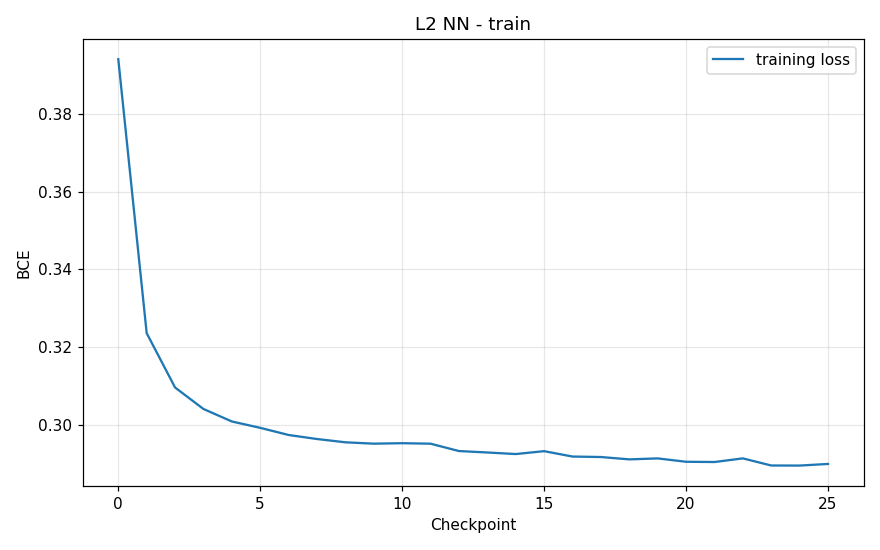

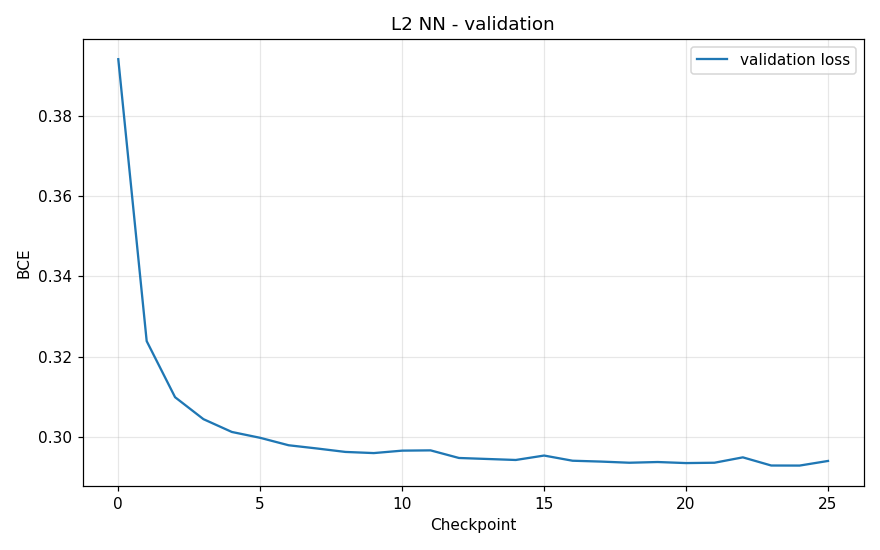

In [9]:
nn_result = train_encoded_nn(
    encoded_fit, y_train[train_indices], encoded_valid, y_train[valid_indices],
    hidden_dim=nn_hidden_dim, epochs=nn_epochs, batch_size=nn_batch_size,
    gamma=nn_gamma, lambda_=nn_lambda, seed=seed, check_every=nn_check_every)
nn_holdout_scores = predict_encoded_nn(encoded_holdout, nn_result["w1"], nn_result["w2"])
nn_holdout_metrics = classification_metrics(
    y_train[holdout_indices], nn_holdout_scores, nn_result["threshold"])
print("Best epoch / threshold:", nn_result["best_epoch"], nn_result["threshold"])
print_metrics("L2 NN validation", nn_result["valid_metrics"])
print_metrics("L2 NN holdout", nn_holdout_metrics)
plot_draw([row["train_ce"] for row in nn_result["history"]],
          "training loss", "L2 NN - train", "Checkpoint", "BCE")
plot_draw([row["valid_ce"] for row in nn_result["history"]],
          "validation loss", "L2 NN - validation", "Checkpoint", "BCE")
del encoded_fit, encoded_valid, encoded_holdout, nn_holdout_scores

### Full training

In [10]:
nn_full_schema = fit_preprocessor(
    x_selected, selected_feature_names, keep_all_features=True)
nn_full_tx = transform_nn_input(
    x_selected, nn_full_schema, "onehot_missing")
nn_full_result = train_encoded_nn_full(
    nn_full_tx, y_train, lambda_=nn_lambda, epochs=nn_result["best_epoch"],
    hidden_dim=nn_hidden_dim, batch_size=nn_batch_size,
    gamma=nn_gamma, seed=seed, check_every=nn_check_every)
print("Full training rows / inputs:", nn_full_tx.shape)
print("Prediction threshold:", nn_result["threshold"])
del nn_full_tx


full-data epoch   1: train_bce=0.37726, objective=0.37817
full-data epoch   5: train_bce=0.31524, objective=0.31623
full-data epoch  10: train_bce=0.30476, objective=0.30579
full-data epoch  15: train_bce=0.29985, objective=0.30091
full-data epoch  20: train_bce=0.29743, objective=0.29851
full-data epoch  25: train_bce=0.29584, objective=0.29693
full-data epoch  30: train_bce=0.29487, objective=0.29598
full-data epoch  35: train_bce=0.29417, objective=0.29530
full-data epoch  40: train_bce=0.29344, objective=0.29458
full-data epoch  45: train_bce=0.29287, objective=0.29401
full-data epoch  50: train_bce=0.29578, objective=0.29693
full-data epoch  55: train_bce=0.29199, objective=0.29316
full-data epoch  60: train_bce=0.29356, objective=0.29473
full-data epoch  65: train_bce=0.29104, objective=0.29223
full-data epoch  70: train_bce=0.29069, objective=0.29188
full-data epoch  75: train_bce=0.29056, objective=0.29176
full-data epoch  80: train_bce=0.29093, objective=0.29214
full-data epoc

### Save model

In [11]:
os.makedirs("output", exist_ok=True)
np.savez_compressed(
    "output/nn_model.npz",
    w1=nn_full_result["w1"], w2=nn_full_result["w2"],
    raw_feature_indices=raw_feature_indices,
    schema=np.array(nn_full_schema, dtype=object),
    threshold=nn_result["threshold"])
print("Model saved: output/nn_model.npz")


Model saved: output/nn_model.npz


## Results

In [12]:
linear_f1s = [metrics["f1"] for metrics in linear_fold_metrics]
print(f"Linear SVM five-fold F1: {np.mean(linear_f1s):.4f} +/- {np.std(linear_f1s):.4f}")
for method_name, metrics in [
    ("RBF SVM validation", rbf_metrics),
    ("MSE NN validation", mse_metrics),
    ("Sigmoid NN validation", ce_metrics),
    ("L2 LR validation", lr_result["valid_metrics"]),
    ("L2 LR holdout", lr_holdout_metrics),
    ("L2 NN validation", nn_result["valid_metrics"]),
    ("L2 NN holdout", nn_holdout_metrics),
]:
    print_metrics(method_name, metrics)

Linear SVM five-fold F1: 0.3505 +/- 0.0016
RBF SVM validation: accuracy=0.8924, balanced_accuracy=0.5917, precision=0.3373, recall=0.2266, f1=0.2711
  TP=1313, TN=57252, FP=2580, FN=4482
MSE NN validation: accuracy=0.8683, balanced_accuracy=0.7233, precision=0.3451, recall=0.5472, f1=0.4233
  TP=3171, TN=53815, FP=6017, FN=2624
Sigmoid NN validation: accuracy=0.8684, balanced_accuracy=0.7235, precision=0.3453, recall=0.5475, f1=0.4235
  TP=3173, TN=53817, FP=6015, FN=2622
L2 LR validation: accuracy=0.8688, balanced_accuracy=0.7411, precision=0.3536, recall=0.5859, f1=0.4410
  TP=2547, TN=40217, FP=4657, FN=1800
L2 LR holdout: accuracy=0.8675, balanced_accuracy=0.7414, precision=0.3509, recall=0.5882, f1=0.4396
  TP=2557, TN=40144, FP=4730, FN=1790
L2 NN validation: accuracy=0.8832, balanced_accuracy=0.7213, precision=0.3823, recall=0.5247, f1=0.4424
  TP=2281, TN=41189, FP=3685, FN=2066
L2 NN holdout: accuracy=0.8814, balanced_accuracy=0.7183, precision=0.3759, recall=0.5204, f1=0.4365